Objective : The objective of this case study is to predict the flower class type.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [2]:
import pathlib
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower',origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir+'/flower_photos')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


In [3]:
data_dir

PosixPath('/root/.keras/datasets/flower/flower_photos')

In [4]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


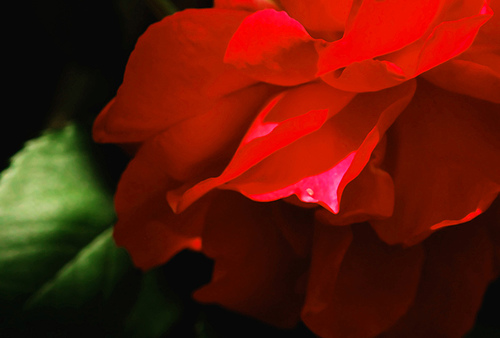

In [5]:
roses = list(data_dir.glob('roses/*'))
PIL.Image.open(str(roses[0]))

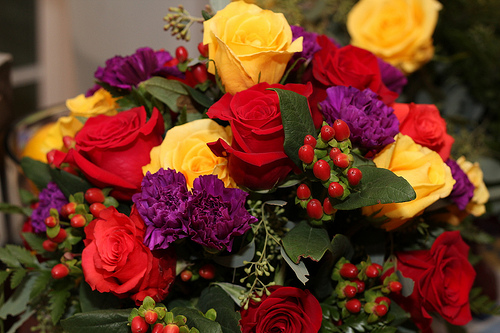

In [6]:
PIL.Image.open(str(roses[1]))

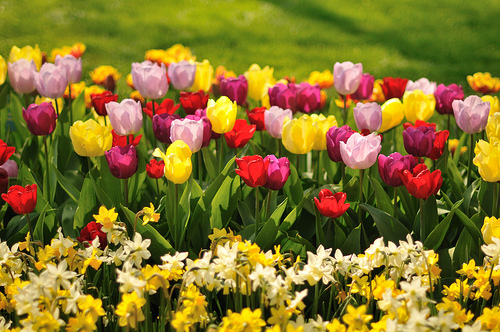

In [7]:
tulips = list(data_dir.glob('tulips/*'))
PIL.Image.open(str(tulips[0]))

In [8]:
batch_size = 32
img_height = 180
img_width = 180

In [9]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [10]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [11]:
class_names = train_ds.class_names
print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


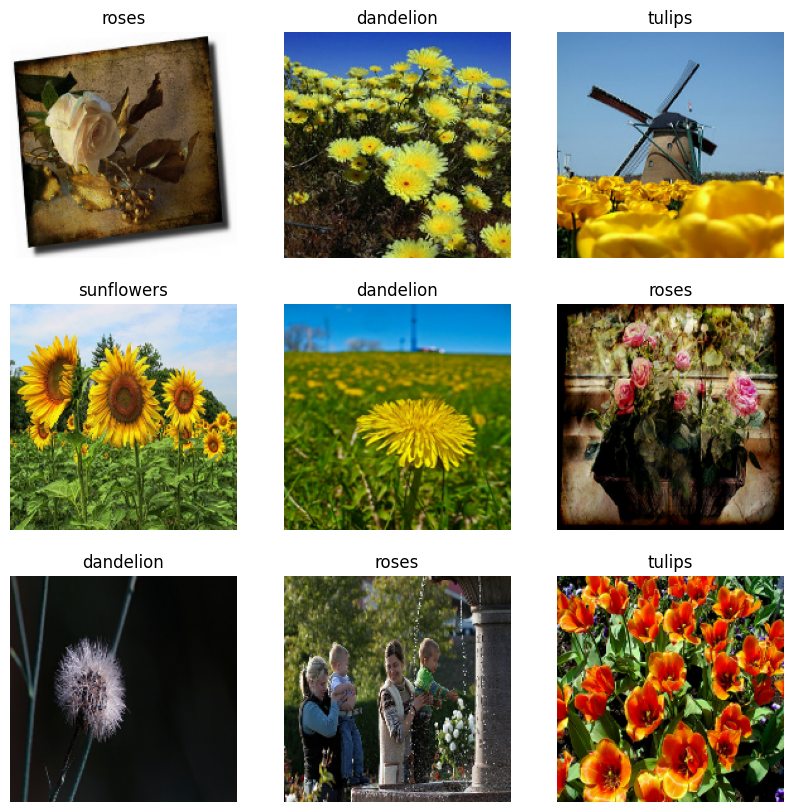

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [13]:
for image_batch, labels_batch in train_ds :
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 180, 180, 3)
(32,)


In [14]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [15]:
normalization_layer = layers.Rescaling(1./255)
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
print(np.min(first_image), np.max(first_image))

0.0 1.0


The model will have 3 convolution blocks with a max pool layer in each of them

In [16]:
num_classes = 5

model = Sequential([
    layers.Rescaling(1./255, input_shape=(img_width, img_height,3)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)

    ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
epochs = 10

history = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = epochs
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.3723 - loss: 1.4331 - val_accuracy: 0.4360 - val_loss: 1.2570
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.5678 - loss: 1.0650 - val_accuracy: 0.5845 - val_loss: 0.9887
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.6679 - loss: 0.8532 - val_accuracy: 0.6267 - val_loss: 0.9540
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.7510 - loss: 0.6634 - val_accuracy: 0.6117 - val_loss: 1.0477
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.8321 - loss: 0.4545 - val_accuracy: 0.6594 - val_loss: 0.9600
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9016 - loss: 0.2943 - val_accuracy: 0.6172 - val_loss: 1.2079
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.9520 - loss: 0.1537 - val_accuracy: 0.6526 - val_loss: 1.2720
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.9802 - loss: 0.0846 - val_accuracy: 0.6744 - v

Text(0.5, 1.0, 'Training and Validation Accuracy')

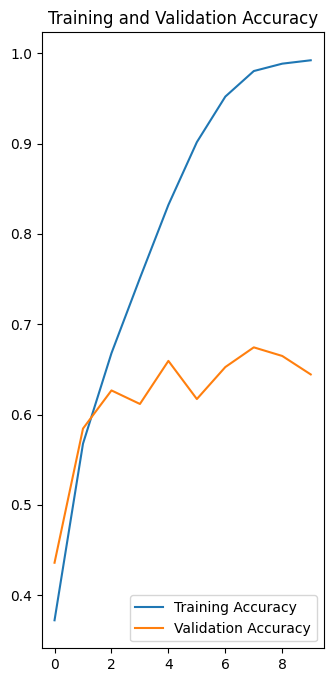

In [20]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

epochs_range = range(epochs)

plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

Conclusion :

Training accuracy is going around 98% whereas validation accuracy is not even touching 70%. This shows that the CNN model is overfitting and not performing well when we build complex model. Let's see how this overfitting problem can be solved using some other model such as RESNET.

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import PIL
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import pathlib

In [22]:
# Downloading the dataset

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)

data_dir = pathlib.Path(data_dir+'/flower_photos')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


In [23]:
#Creating Training and Validation dataset

img_height, img_width = 180, 180
batch_size = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(data_dir, validation_split=0.2, subset = "training", seed = 456, image_size = (img_height, img_width), batch_size = batch_size)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset = "validation",
    seed=456,
    image_size=(img_height,img_width),
    batch_size=batch_size
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


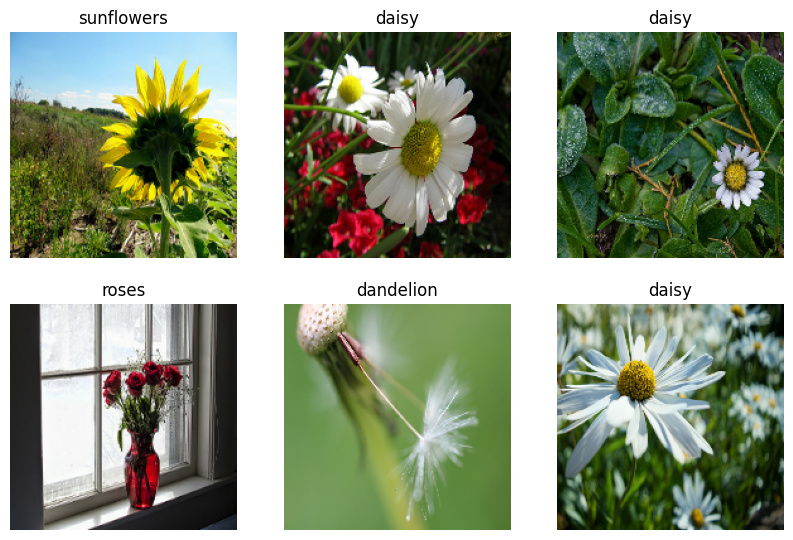

In [24]:
# Visualize the data

import matplotlib.pyplot as plt

class_names = train_ds.class_names
plt.figure(figsize=(10,10))
for images,labels in train_ds.take(1):
  for i in range(6):
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [31]:
resnet_model = Sequential()

resnet_model.add(keras.Input(shape=(180,180,3)))

In [32]:
# Using a pre-trained model for RESNET
from tensorflow.keras.layers import Flatten


pretrained_model = tf.keras.applications.ResNet50(include_top=False, input_shape=(180,180,3),
                                                  pooling='avg',
                                                  classes=5,
                                                  weights='imagenet', name='rnet50')

for layer in pretrained_model.layers :
  layer.trainable = False

resnet_model.add(pretrained_model)

resnet_model.add(Flatten())
resnet_model.add(Dense(512, activation='relu'))
resnet_model.add(Dense(5, activation='softmax'))

In [33]:
resnet_model.compile(optimizer=Adam(learning_rate=0.001), loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), metrics=['accuracy'])

resnet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnet50 (Functional)             │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,639,365 (93.99 MB)

 Trainable params: 1,051,653 (4.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [35]:
#Training the model using epochs

epochs = 10

history = resnet_model.fit(train_ds, validation_data = val_ds, epochs = epochs)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 557s 6s/step - accuracy: 0.7783 - loss: 0.7249 - val_accuracy: 0.8638 - val_loss: 0.3901
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 544s 6s/step - accuracy: 0.8965 - loss: 0.2810 - val_accuracy: 0.8678 - val_loss: 0.3819
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 545s 6s/step - accuracy: 0.9452 - loss: 0.1518 - val_accuracy: 0.8706 - val_loss: 0.3957
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 573s 6s/step - accuracy: 0.9612 - loss: 0.1063 - val_accuracy: 0.8529 - val_loss: 0.4591
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 545s 6s/step - accuracy: 0.9830 - loss: 0.0609 - val_accuracy: 0.8692 - val_loss: 0.4561
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 567s 6s/step - accuracy: 0.9860 - loss: 0.0502 - val_accuracy: 0.8719 - val_loss: 0.4436
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 572s 6s/step - accuracy: 0.9966 - loss: 0.0229 - val_accuracy: 0.8692 - val_loss: 0.4544
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 509s 6s/step - accuracy: 0.9976 - loss: 0.0161 - val_accuracy: 0.8883 - v

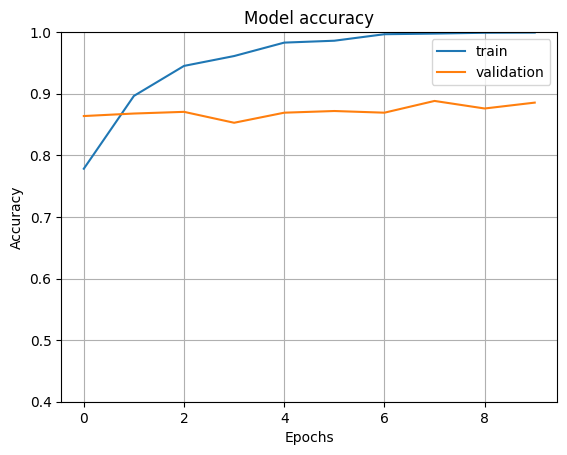

In [36]:
#Plotting the graph for comparison of training and validation accuracy

fig1 = plt.gcf()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.axis(ymin=0.4, ymax=1)
plt.grid()
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['train','validation'])
plt.show()

We can clearly observe that using RESNET our validation accuracy has improved and is close to 90% where it was not even 70% when we built the model using CNN.
Hence, RESNET outperforms CNN when we are dealing with large datasets of images.

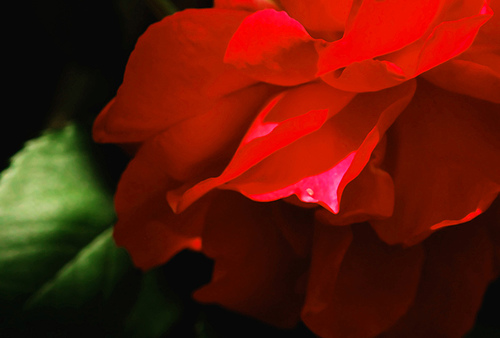

In [37]:
# Visualizing images of Roses and Tulips

import cv2

roses = list(data_dir.glob('roses/*'))
image = cv2.imread(str(roses[0]))
image_resized = cv2.resize(image, (img_height, img_width))
image_1 = np.expand_dims(image_resized, axis=0)
PIL.Image.open(str(roses[0]))

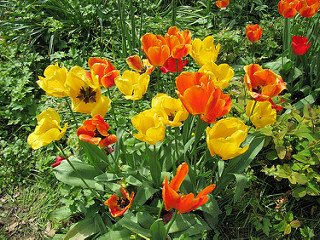

In [38]:
tulips = list(data_dir.glob('tulips/*'))
image = cv2.imread(str(tulips[1]))
image_resized = cv2.resize(image, (img_height, img_width))
image_2 = np.expand_dims(image_resized, axis=0)
PIL.Image.open(str(tulips[1]))

In [39]:
#predicting results

pred_1 = resnet_model.predict(image_1)
pred_2 = resnet_model.predict(image_2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step


In [40]:
output_class = class_names[np.argmax(pred_1)]
print("The predicted class is", output_class)

The predicted class is roses


In [41]:
output_class = class_names[np.argmax(pred_2)]
print("The predicted class is", output_class)

The predicted class is tulips


**Conclusion** : It is clear that RESNET has outperformed CNN model when we are dealing with large dataset of images.

In [42]:
# Deployment using Gradio

!pip install -q gradio

In [76]:
from PIL import Image

def predict_image(img):
  # If image is numpy array, convert to PIL first
  if isinstance(img, np.ndarray):
      image = Image.fromarray(img)
  # Resize with interpolation
  resized = image.resize((180, 180), Image.Resampling.LANCZOS)

  # Convert back to numpy array
  arr = np.array(resized)

  # Now reshape safely (180x180x3 for RGB)
  img_4d = arr.reshape(-1,180, 180, 3)
  prediction = resnet_model.predict(img_4d)[0]
  return { class_names[i] : float(prediction[i]) for i in range(5)}

In [77]:
import gradio as gr

image = gr.Image(image_mode='RGB',type="numpy")
label = gr.Label(num_top_classes=5)

gr.Interface(fn=predict_image,
             inputs=image,
             outputs=label).launch(debug='False')

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://819e4023b0912fbe01.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://819e4023b0912fbe01.gradio.live
